In [1]:
   import wfdb
   import numpy as np
   import matplotlib.pyplot as plt

   # Load record 100 from the MIT-BIH Arrhythmia Database (streams from PhysioNet)
   record = wfdb.rdrecord('100', pn_dir='mitdb')

   print("Sampling rate (Hz):", record.fs)
   print("Channels:", record.sig_name)
   print("Units:", record.units)
   print("Shape (samples, channels):", record.p_signal.shape)

Sampling rate (Hz): 360
Channels: ['MLII', 'V5']
Units: ['mV', 'mV']
Shape (samples, channels): (650000, 2)


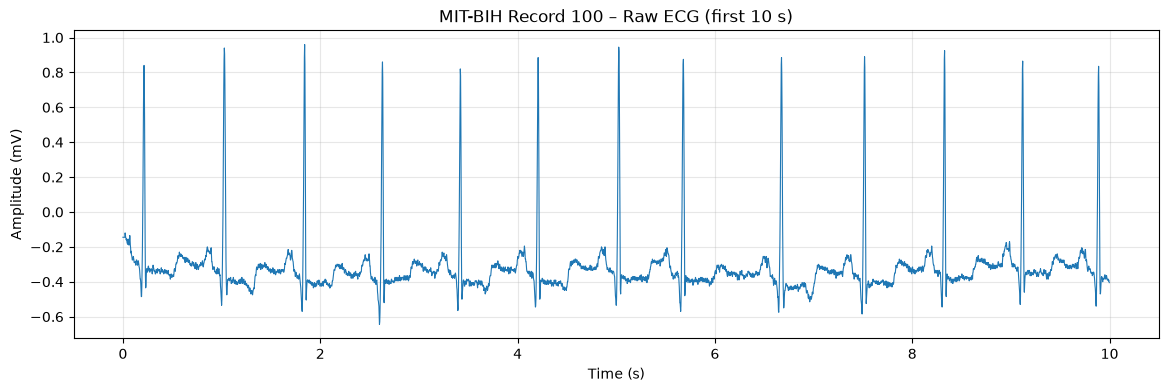

In [2]:
   fs = record.fs                 # samples per second
   ecg = record.p_signal[:, 0]    # first channel (MLII lead)
   t = np.arange(len(ecg)) / fs   # time axis in seconds

   n = 10 * fs                    # 10 seconds of samples
   plt.figure(figsize=(14, 4))
   plt.plot(t[:n], ecg[:n], linewidth=0.8)
   plt.title("MIT-BIH Record 100 – Raw ECG (first 10 s)")
   plt.xlabel("Time (s)")
   plt.ylabel("Amplitude (mV)")
   plt.grid(True, alpha=0.3)
   plt.show()

In [3]:
ann = wfdb.rdann('100', 'atr', pn_dir='mitdb')

print("Number of annotations:", len(ann.sample))
print("Beat label types:", sorted(set(ann.symbol)))

Number of annotations: 2274
Beat label types: ['+', 'A', 'N', 'V']


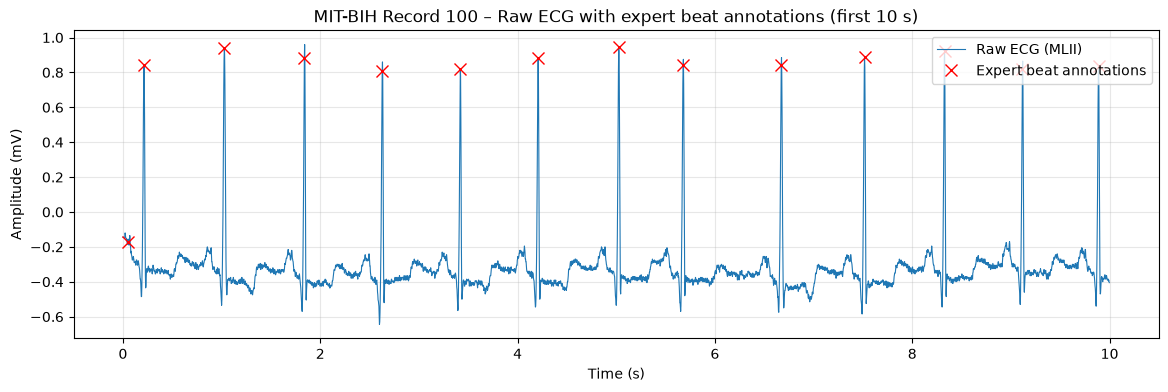

In [4]:
import os
os.makedirs('figures', exist_ok=True)

mask = ann.sample < n                      # annotations in the first 10 s
beat_idx = ann.sample[mask]

plt.figure(figsize=(14, 4))
plt.plot(t[:n], ecg[:n], linewidth=0.8, label="Raw ECG (MLII)")
plt.plot(t[beat_idx], ecg[beat_idx], 'rx', markersize=8, label="Expert beat annotations")
plt.title("MIT-BIH Record 100 – Raw ECG with expert beat annotations (first 10 s)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.savefig('figures/01_raw_ecg_annotated.png', dpi=150, bbox_inches='tight')
plt.show()

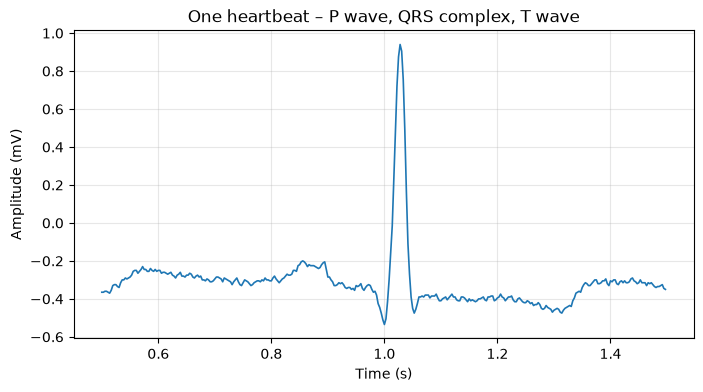

In [5]:
start, end = int(0.5 * fs), int(1.5 * fs)   # 0.5 s to 1.5 s

plt.figure(figsize=(8, 4))
plt.plot(t[start:end], ecg[start:end], linewidth=1.2)
plt.title("One heartbeat – P wave, QRS complex, T wave")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.grid(True, alpha=0.3)
plt.savefig('figures/02_single_heartbeat.png', dpi=150, bbox_inches='tight')
plt.show()